# Bij welke groep-4-sterren hadden we een hete reus kunnen vinden?

## Kort antwoord
Er zijn concrete sterren waarvoor we dat kunnen onderbouwen. Van de **256 sterren met 274 groep-4-planeten** konden we 52 sterren koppelen aan gepubliceerde detectietests van de California Legacy Survey (CLS). In een duidelijk omschreven proef wordt bij **48 van die 52 sterren minstens 90%** van de testsignalen teruggevonden. Bij **24 sterren** ligt zelfs de ondergrens van een 95%-Wilsoninterval boven 90%.

Bij 22 van die 24 sterren staat in onze huidige dataset geen groep-1-metgezel geregistreerd. Ook zijn daar geen bevestigde begeleiders met de massa en omlooptijd van ons proefgebied opgenomen. De twee andere sterren zijn HD 187123 en HD 38529, die wel een bekende nabije reus hebben.

**Dit ondersteunt Leo's redenering:** voor een aantoonbaar goed onderzochte deelverzameling is het niet genoeg om een ontbrekende hete reus zomaar aan ontbrekende waarnemingen toe te schrijven. Het bewijst niet dat er bij elke individuele ster zeker geen hete reus aanwezig is.

## Hoe weten we of een onontdekte planeet vindbaar zou zijn?
Rosenthal en collega's (2021) voegden kunstmatige planeetsignalen toe aan de echte snelheidsmetingen van iedere ster. Vervolgens liet hun zoekprocedure zien of die signalen werden teruggevonden. Dit heet een *injection–recovery test*. Het is een praktisch antwoord op: 'Als deze extra planeet er was geweest, zou deze meetreeks hem laten zien?'

Wij voerden geen nieuwe simulaties uit, maar selecteerden en telden de gepubliceerde tests opnieuw. Het zijn de metingen en zoekprocedure van de publicatie uit 2021, niet automatisch alle latere waarnemingen.

## Onze afbakening
Er bestaat geen detectiekans voor 'een willekeurige hete gasreus' zonder iets over haar massa en baan te zeggen. Daarom kiezen we een herkenbaar proefgebied:

- **Minimum-massa M sin i van 0,3 tot 3 Jupitermassa's.** Een echte massa bij een ongunstige baanhelling kan een kleiner waarneembaar signaal geven; daarom geldt deze uitspraak voor minimum-massa.
- **Omlooptijd van 2 tot 20 dagen.** Dat omvat ook de eerder besproken banen van 14 en 18 dagen. Dit is een detectieproef, geen nieuwe grens voor onze SOM-groep 1.
- De excentriciteiten en overige baanparameters zijn die van de oorspronkelijke gepubliceerde tests; we wegen die niet opnieuw.
- Minstens 20 geselecteerde tests per ster. De feitelijke aantallen liggen hier hoger.

Niet alle groep-1-planeten vallen in dit proefgebied. Een lichtere gasrijke planeet, een baan korter dan 2 of langer dan 20 dagen, of een uitzonderlijk ongunstige baanfase/meetverdeling vraagt een afzonderlijke test. Ook instraling en stertype zijn niet gebruikt om deze testsignalen aan een SOM-groep toe te wijzen.

De terugvindfractie is een gemiddelde over de eindige verzameling tests in dit gebied. Zij is **geen gegarandeerde detectiekans op ieder afzonderlijk punt** van het massa-baanvlak.


## Bronnen en koppeling
De vaste PCA-SOM blijft ongewijzigd. Van de groep-4-planeten zijn er 250 via radiale snelheid ontdekt; de overige ontdekkingsmethoden zijn apart geteld. Een RV-ontdekking alleen is geen bewijs van goede gevoeligheid voor iedere korte baan.

Voor de 256 gaststerren zijn NASA-hostnamen en hun HD/HIP-aliassen gekoppeld aan de sterren in CLS. Alleen unieke, exacte overeenkomsten na normalisatie van catalogusnotatie tellen mee; er zijn geen fuzzy matches gebruikt. Er zijn 52 koppelingen met openbare recovery-bestanden. Namen en alle niet-gekoppelde sterren staan in de uitvoer.

**De overige 204 sterren zijn hier niet beoordeeld.** Dat betekent niet dat ze onvoldoende gemeten zijn. Andere surveys of recentere publicaties kunnen ook detectiegrenzen bevatten; deze eerste controle doorzoekt niet de volledige literatuur per ster.

- [Rosenthal et al. 2021, bronpublicatie](https://authors.library.caltech.edu/records/xchq8-ac416)
- [CLSI: gepubliceerde tests](https://github.com/leerosenthalj/CLSI/tree/master/completeness/recoveries_all)
- [CLSII: sterparameters en meetstatistieken](https://github.com/leerosenthalj/CLSII/tree/master/legacy_tables)

De exacte bronlinks en hashes van de 52 gedownloade testbestanden staan in `detectability_sources/download_provenance.json`. Het PCA-model is met een hash geïdentificeerd en niet veranderd.

## Opnieuw uitvoeren
Open dit notebook in de uitgepakte projectmap. De oorspronkelijke recovery-bestanden zitten in `detectability_sources/recoveries`. Installeer zo nodig `pip install -r requirements.txt`.

In [1]:
import contextlib,io,json
import pandas as pd
from IPython.display import display,Markdown,Image
from analysis import ROOT
import detectability_group4
with contextlib.redirect_stdout(io.StringIO()):
    result=detectability_group4.analyze()
out=ROOT/'results_detectability_group4'
table=pd.read_csv(out/'detectiekans_alle_groep4_sterren.csv')
assert len(table)==256 and table.ster.is_unique
assert result['tested_hosts']==52 and result['conservative_hosts']==24
display(pd.DataFrame({'Stap':['Sterren met groep-4-planeet','Met gepubliceerde CLS-tests','Terugvindfractie minstens 90%','Ook 95%-Wilsonondergrens minstens 90%','Nog niet beoordeeld in deze bron'],'Aantal':[256,52,result['strong_hosts'],result['conservative_hosts'],result['not_assessed_hosts']]}))

,Stap,Aantal
0,Sterren met groep-4-planeet,256
1,Met gepubliceerde CLS-tests,52
2,Terugvindfractie minstens 90%,48
3,Ook 95%-Wilsonondergrens minstens 90%,24
4,Nog niet beoordeeld in deze bron,204


## Voorbeelden
De punten geven de terugvindfractie; de streepjes geven 95%-Wilsonintervallen. Bijvoorbeeld 56/56 betekent dat alle 56 tests in ons proefgebied zijn teruggevonden. Dat bewijst geen detectiekans van exact 100%: er zijn maar 56 tests en niet iedere mogelijke baan is afzonderlijk geprobeerd.

Het Wilsoninterval beschrijft de onzekerheid door het eindige aantal tests in dit gebied onder een binomiale benadering. Het omvat niet alle onzekerheid in steractiviteit, de zoekprocedure, de gekozen parameterverdeling of ontbrekende latere waarnemingen. De intervallen zijn per ster, niet simultaan gecorrigeerd voor de selectie van meerdere sterren.

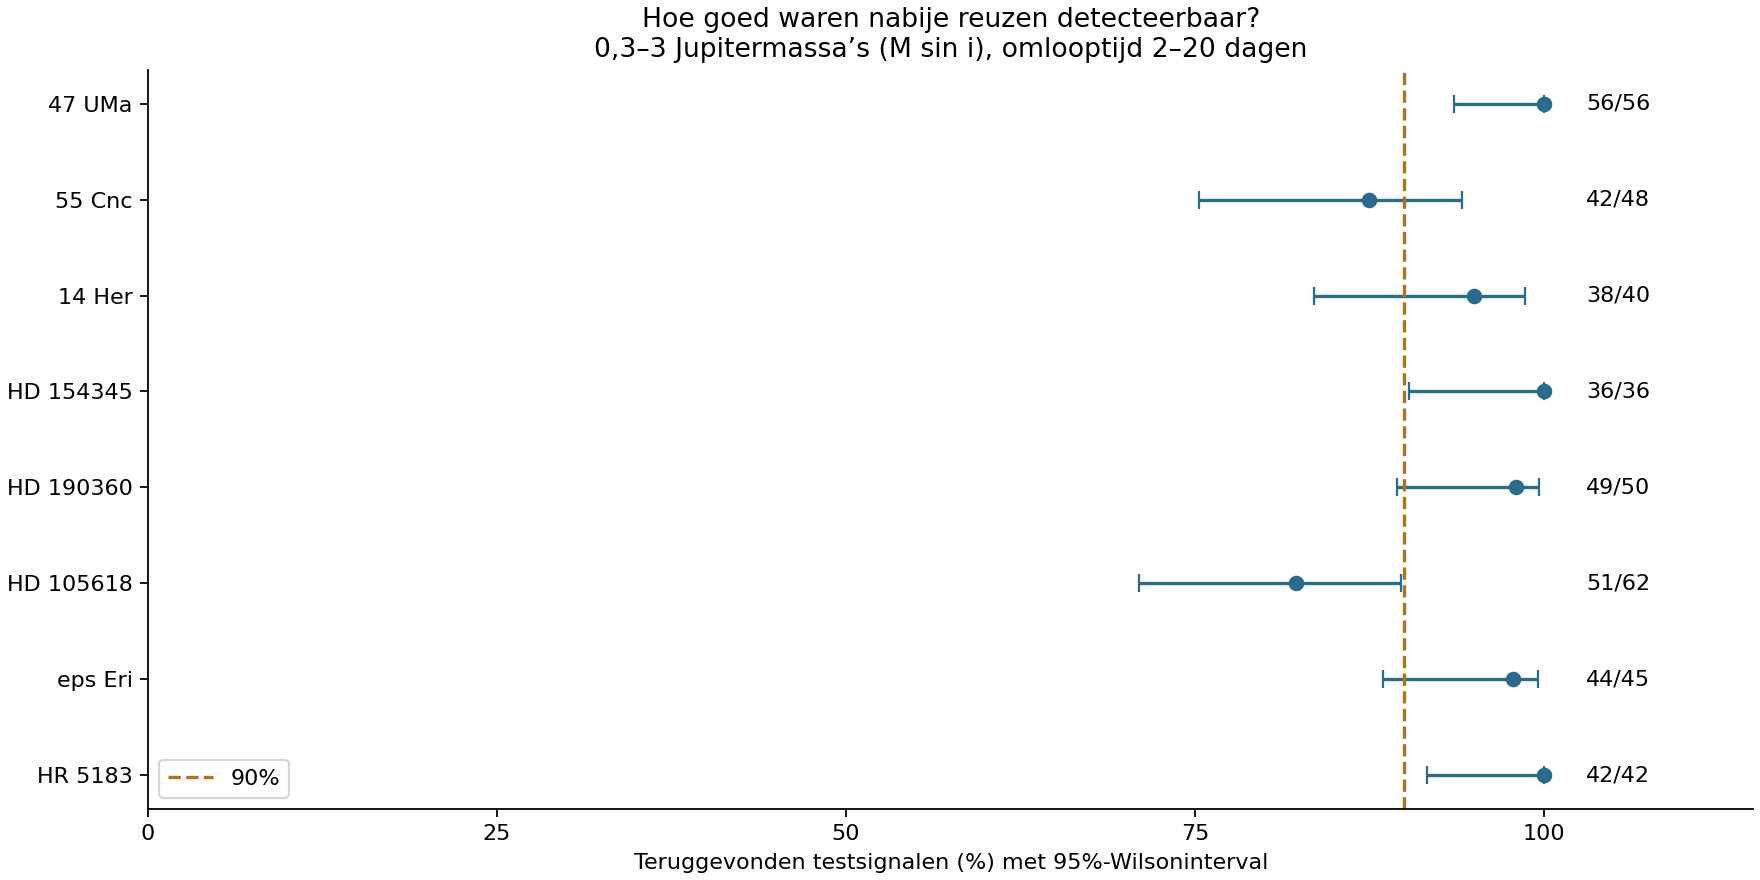

In [2]:
display(Image(filename=str(out/'detectiekans_voorbeelden.png')))

In [3]:
examples=['47 UMa','HD 154345','HR 5183','14 Her','55 Cnc','HD 105618']
v=table.set_index('ster').loc[examples,['N_metingen','baseline_jaren','testsignalen','teruggevonden','terugvindfractie','wilson95_laag','wilson95_hoog','groep1_metgezel_bekend']].copy()
for c in ['terugvindfractie','wilson95_laag','wilson95_hoog']:v[c]*=100
display(v.round(2))

,N_metingen,baseline_jaren,testsignalen,teruggevonden,terugvindfractie,wilson95_laag,wilson95_hoog,groep1_metgezel_bekend
ster,,,,,,,,
47 UMa,421.0,31.76,56,56,100.00,93.58,100.00,False
HD 154345,141.0,22.18,36,36,100.00,90.36,100.00,False
HR 5183,305.0,22.51,42,42,100.00,91.62,100.00,False
14 Her,307.0,22.18,40,38,95.00,83.50,98.62,False
55 Cnc,646.0,30.30,48,42,87.50,75.30,94.14,False
HD 105618,16.0,3.27,62,51,82.26,70.96,89.79,False


## De 24 sterren met de sterkste onderbouwing in deze proef
Deze selectie gebruikt een terugvindfractie met een 95%-Wilsonondergrens van minstens 90%. De grens is onze praktische keuze. Ook deze lijst is geen bewijs dat iedere denkbare hete gasreus zou zijn gevonden.

'Groep-1-metgezel bekend' slaat op onze huidige vaste groepsindeling. De twee bekende nabije reuzen in deze lijst zijn bovendien rechtstreeks in de volledige NASA-momentopname terug te vinden: HD 187123 b en HD 38529 b.

In [4]:
conservative=table[table.conservatief_90pct].copy()
display(conservative[['ster','groep4_planeten','testsignalen','teruggevonden','wilson95_laag','groep1_metgezel_bekend']].assign(wilson95_laag_pct=conservative.wilson95_laag*100).drop(columns='wilson95_laag').round(2).reset_index(drop=True))

,ster,groep4_planeten,testsignalen,teruggevonden,groep1_metgezel_bekend,wilson95_laag_pct
0,47 UMa,47 UMa d,56,56,False,93.58
1,HD 10697,HD 10697 b,44,44,False,91.97
2,HD 110537,HD 110537 b,39,39,False,91.03
3,HD 114783,HD 114783 c,42,42,False,91.62
4,HD 12661,HD 12661 c,39,39,False,91.03
5,HD 128311,HD 128311 c,42,42,False,91.62
6,HD 134987,HD 134987 c,36,36,False,90.36
7,HD 13931,HD 13931 b,37,37,False,90.59
8,HD 141399,HD 141399 e,35,35,False,90.11
9,HD 154345,HD 154345 b,36,36,False,90.36


## Alle 52 beoordeelde sterren
Ook sterren die de gekozen grens niet halen zijn hier opgenomen. Een lager resultaat betekent niet dat iedere hete reus onvindbaar is; alleen dat ons gehele proefgebied gemiddeld minder goed wordt teruggevonden.

In [5]:
tested=table[table.bron_getest].copy()
display(tested[['ster','N_metingen','baseline_jaren','testsignalen','teruggevonden','terugvindfractie','sterke_aanwijzing_90pct','conservatief_90pct']].round(3).reset_index(drop=True))

,ster,N_metingen,baseline_jaren,testsignalen,teruggevonden,terugvindfractie,sterke_aanwijzing_90pct,conservatief_90pct
0,14 Her,307.0,22.184,40,38,0.950,True,False
1,47 UMa,421.0,31.765,56,56,1.000,True,True
2,55 Cnc,646.0,30.299,48,42,0.875,False,False
3,GJ 15 A,191.0,21.695,52,47,0.904,True,False
4,GJ 179,51.0,18.921,44,43,0.977,True,False
5,GJ 849,106.0,22.056,40,39,0.975,True,False
6,HD 105618,16.0,3.269,62,51,0.823,False,False
7,HD 10697,83.0,22.880,44,44,1.000,True,True
8,HD 110537,64.0,21.068,39,39,1.000,True,True
9,HD 114783,132.0,20.994,42,42,1.000,True,True


## Wat betekent dit voor ons eerdere resultaat van 13 uit 274?
Die eerdere telling ging over **planeten** uit groep 4 met een bekende groep-1-metgezel. Hier tellen we **sterren** en onderzoeken we bovendien alleen een specifieke gepubliceerde meetreeks en een omschreven detectieproef. De aantallen mogen niet rechtstreeks als dezelfde populatie worden behandeld.

De huidige uitkomst maakt duidelijk dat de afwezigheid van een bekende hete reus bij sommige sterren betekenisvoller is dan bij andere. Bij 47 UMa bijvoorbeeld zijn 56 van 56 tests teruggevonden, bij HD 105618 51 van 62. 'Er is een buitenplaneet gevonden' geeft dus geen gelijke detectiezekerheid voor iedere ster.

De 22 conservatief geselecteerde sterren zonder bekende groep-1-metgezel vormen een bruikbare deelverzameling voor vervolgonderzoek. Dit is geen volledige occurrence-analyse: de detectiekans moet over een expliciete populatie van mogelijke metgezellen worden gemiddeld; selectiebias, groepen met geschatte kenmerken, de onzekerheid in groepslidmaatschap en verschillen tussen surveys vragen verdere aandacht.

Een volgende gerichte uitbreiding is de oorspronkelijke groep-1-planeeteigenschappen als detectiesignalen door de meetreeksen te laten lopen, of fijnere gepubliceerde recoverykaarten te gebruiken. Dan sluiten detectievragen nog beter aan op onze eigen indeling. Dat is hier niet uitgevoerd.

## Validatie en bestanden
Er zijn 52 originele recovery-bestanden opgehaald, met URL en SHA-256 bewaard. De gebruikte subset van tests is per ster ook als afzonderlijke CSV opgeslagen. Namen, planeetaantallen, minima, massa-eenheden, tellingen en figuurwaarden worden uit dezelfde code opgebouwd.

- `detectability_group4.py`: volledige analyse.
- `results_detectability_group4/detectiekans_alle_groep4_sterren.csv`: alle 256 sterren, inclusief niet-beoordeelde gevallen.
- `conservatieve_selectie.csv`: de 24 geselecteerde sterren.
- `geteste_sterren.csv`: alle 52 beoordeelde sterren.
- `detectability_sources`: naamkoppelingen, meetstatistieken, oorspronkelijke tests en bronmetadata.

De interpretatie is bewust beperkt tot de beschreven proef en bron. De oorspronkelijke indelingen, kaarten en eerdere tellingen zijn bewaard.
